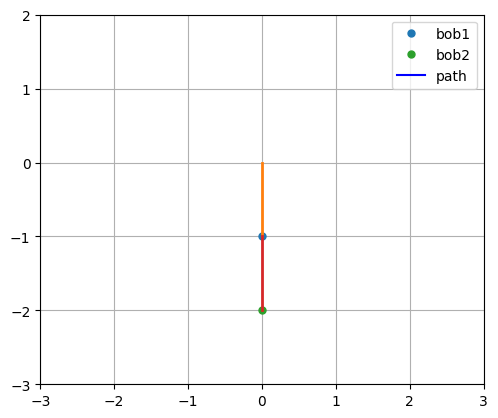

In [2]:
import sympy as smp
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
# 1. Setup Symbols
m1, m2, t, l1, l2 = smp.symbols('m1 m2 t l1 l2')
th1, th2 = smp.symbols('th1 th2', cls=smp.Function)
th1 = th1(t)
th2 = th2(t)

# 2. Kinematics
x1 = l1 * smp.sin(th1)
y1 = -l1 * smp.cos(th1)
x2 = l1 * smp.sin(th1) + l2 * smp.sin(th2)
y2 = -l1 * smp.cos(th1) - l2 * smp.cos(th2)

# 3. Lagrangian Mechanics
T = m1 * (smp.diff(x1, t)**2 + smp.diff(y1, t)**2) / 2 + m2 * (smp.diff(x2, t)**2 + smp.diff(y2, t)**2) / 2
V = (m1 * y1 * 9.8 + m2 * y2 * 9.8)
L = T - V

dth1 = smp.diff(th1, t)
dth2 = smp.diff(th2, t)
a1 = smp.diff(th1, t, 2)
a2 = smp.diff(th2, t, 2)

LE1 = smp.diff(L, th1) - smp.diff(smp.diff(L, dth1), t)
LE2 = smp.diff(L, th2) - smp.diff(smp.diff(L, dth2), t)

# Solve for accelerations
al = smp.solve([LE1, LE2], [a1, a2])
al1 = al[a1].simplify()
al2 = al[a2].simplify()

# 4. Numerical Conversion
# Fixed the typo here: k1 uses al1, k2 uses al2
k1 = al1.subs([(l1, 1), (l2, 1), (m1, 2), (m2, 3)])
k2 = al2.subs([(l1, 1), (l2, 1), (m1, 2), (m2, 3)])

# Lambdify (including t even if it's not explicitly in the equation)
ac1 = smp.lambdify([t, th1, th2, dth1, dth2], k1)
ac2 = smp.lambdify([t, th1, th2, dth1, dth2], k2)

# 5. ODE Integration
def ds(tim, S):
    theta1, theta2, omega1, omega2 = S
    return [
        omega1, 
        omega2, 
        ac1(tim, theta1, theta2, omega1, omega2), 
        ac2(tim, theta1, theta2, omega1, omega2)
    ]

th10, th20 = 0, 0
dth10, dth20 = 2, 0
S0 = (th10, th20, dth10, dth20)

# Run solver with dense_output=True
slon = solve_ivp(ds, [0, 50], S0, method='RK45', dense_output=True, rtol=1e-9)

# 6. Extract Smooth Version
t_smooth = np.linspace(0, 50, 500) # 1000 points for a very smooth curve
sol_smooth = slon.sol(t_smooth)

ta1= sol_smooth[0]
ta2= sol_smooth[1]
x1=np.sin(ta1)
y1=-np.cos(ta1)
x2=np.sin(ta1)+np.sin(ta2)
y2=-np.cos(ta1)-np.cos(ta2)
fig,ax=plt.subplots()
ax.set_aspect('equal')
ax.set_ylim(-3,2)
ax.set_xlim(-3,3)
pend1,=ax.plot([],[],'o',markersize='5',label='bob1')
lin1,=ax.plot([],[],'-',lw=2)
pend2,=ax.plot([],[],'o',markersize='5',label='bob2')
lin2,=ax.plot([],[],'-',lw=2)
path,=ax.plot([],[],color='blue',label='path')
def up(frame):
    pend1.set_data([x1[frame]],[y1[frame]])
    pend2.set_data([x2[frame]],[y2[frame]])
    lin1.set_data([0,x1[frame]],[0,y1[frame]])
    lin2.set_data([x1[frame],x2[frame]],[y1[frame],y2[frame]])
    path.set_data(x2[:frame],y2[:frame])
   
    return (pend1,pend2,lin1,lin2)
ani =FuncAnimation(fig,up,frames=range(0,len(t_smooth)),interval=100,blit=False)
plt.grid()
plt.legend()
HTML(ani.to_jshtml())




Using initial: Random seed (chaotic) (np.float64(1.7213166190998062), np.float64(-0.3840380893017967), np.float64(0.7326885200152802), np.float64(2.034534960236568))


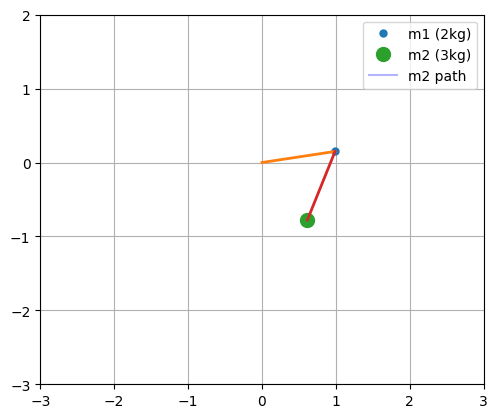

In [11]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. System Parameters
g = 9.8
m1 = 2.0
m2 = 3.0
l1 = 1.0
l2 = 1.0

# 2. Explicit Analytical Equations of Motion
# These are the final differential equations derived from resolving Newtonian forces (or Lagrangian)
def derivatives(t, state):
    th1, th2, w1, w2 = state
    
    delta = th1 - th2
    
    # Denominator (common to both accelerations)
    den1 = (2 * m1 + m2 - m2 * np.cos(2 * th1 - 2 * th2))
    
    # Angular acceleration for theta 1
    num1 = -g * (2 * m1 + m2) * np.sin(th1) - m2 * g * np.sin(th1 - 2 * th2) - \
           2 * np.sin(delta) * m2 * ((w2**2) * l2 + (w1**2) * l1 * np.cos(delta))
    a1 = num1 / (l1 * den1)
    
    # Angular acceleration for theta 2
    num2 = 2 * np.sin(delta) * ((w1**2) * l1 * (m1 + m2) + g * (m1 + m2) * np.cos(th1) + \
           (w2**2) * l2 * m2 * np.cos(delta))
    a2 = num2 / (l2 * den1)
    
    return [w1, w2, a1, a2]

import numpy as np

# (th1, th2, dth1, dth2) — angles in radians, angular velocities in rad/s
cool_initials = [
    ("Both up unstable",       (np.pi/2, np.pi/2, 0.0, 0.0)),
    ("Opposite start",         (np.pi/2, -np.pi/2, 0.0, 0.0)),
    ("High-energy spin",       (0.0, 0.0, 10.0, 0.0)),         # large initial angular speed
    ("Small perturbation",     (np.pi/2, np.pi/2 + 1e-6, 0.0, 0.0)),  # shows sensitivity / divergence
    ("Offset + counter spin",  (2.0, 1.0, 0.0, -5.0)),
    ("One displaced",          (np.pi/3, 0.05, 0.0, 0.0)),
    ("Random seed (chaotic)",  tuple(list(np.random.default_rng(42).uniform(-np.pi, np.pi, 2)) + list(np.random.default_rng(43).normal(0,3,2))))
]

# Example: pick one and run
name, state0 = cool_initials[6]   # change index to try others
print("Using initial:", name, state0)



# 4. ODE Integration
t_span = [0, 50]
t_eval = np.linspace(t_span[0], t_span[1], 500)
sol = solve_ivp(derivatives, t_span, state0, method='RK45', t_eval=t_eval, rtol=1e-9)

# 5. Extract and Plot (Same animation logic as yours)
th1_sol = sol.y[0]
th2_sol = sol.y[1]

x1 = l1 * np.sin(th1_sol)
y1 = -l1 * np.cos(th1_sol)
x2 = x1 + l2 * np.sin(th2_sol)
y2 = y1 - l2 * np.cos(th2_sol)

fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.set_ylim(-3, 2)
ax.set_xlim(-3, 3)

pend1, = ax.plot([], [], 'o', markersize=5, label='m1 (2kg)')
lin1, = ax.plot([], [], '-', lw=2)
pend2, = ax.plot([], [], 'o', markersize=10, label='m2 (3kg)') # Made bigger for visibility
lin2, = ax.plot([], [], '-', lw=2)
path, = ax.plot([], [], color='blue', alpha=0.3, label='m2 path')

def update(frame):
    pend1.set_data([x1[frame]], [y1[frame]])
    pend2.set_data([x2[frame]], [y2[frame]])
    lin1.set_data([0, x1[frame]], [0, y1[frame]])
    lin2.set_data([x1[frame], x2[frame]], [y1[frame], y2[frame]])
    path.set_data(x2[:frame], y2[:frame])
    return (pend1, pend2, lin1, lin2)

ani = FuncAnimation(fig, update, frames=100, interval=100, blit=False)
plt.grid()
plt.legend()
HTML(ani.to_jshtml())

array([ 0.        ,  0.1002004 ,  0.2004008 ,  0.3006012 ,  0.4008016 ,
        0.501002  ,  0.6012024 ,  0.70140281,  0.80160321,  0.90180361,
        1.00200401,  1.10220441,  1.20240481,  1.30260521,  1.40280561,
        1.50300601,  1.60320641,  1.70340681,  1.80360721,  1.90380762,
        2.00400802,  2.10420842,  2.20440882,  2.30460922,  2.40480962,
        2.50501002,  2.60521042,  2.70541082,  2.80561122,  2.90581162,
        3.00601202,  3.10621242,  3.20641283,  3.30661323,  3.40681363,
        3.50701403,  3.60721443,  3.70741483,  3.80761523,  3.90781563,
        4.00801603,  4.10821643,  4.20841683,  4.30861723,  4.40881764,
        4.50901804,  4.60921844,  4.70941884,  4.80961924,  4.90981964,
        5.01002004,  5.11022044,  5.21042084,  5.31062124,  5.41082164,
        5.51102204,  5.61122244,  5.71142285,  5.81162325,  5.91182365,
        6.01202405,  6.11222445,  6.21242485,  6.31262525,  6.41282565,
        6.51302605,  6.61322645,  6.71342685,  6.81362725,  6.91